# Customer Churn & Retention Analysis

This notebook walks through the analysis step by step. The cleaning itself is done in `src/data_cleaning.py`; here I first look at the raw file to show the problems, then analyze the cleaned file.

Run it from the `notebooks/` folder after running `python src/data_cleaning.py` from the project folder.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="white")
pd.set_option("display.max_columns", 30)

## 1. Raw data: a quick look at the problems

In [2]:
raw = pd.read_csv("../data/raw_customer_data.csv")
print("Shape:", raw.shape)
raw.head()

Shape: (4057, 15)


,customer_id,gender,age,tenure_months,contract_type,monthly_charges,total_charges,payment_method,service_type,internet_service,support_tickets,usage_frequency,region,customer_segment,churn
0,CUST-11540,Male,24.0,9,One year,1452.0,13091.94,Credit Card,Mobile + Broadband,DSL,0,21,North,Individual,No
1,CUST-12416,Male,25.0,10,Month-to-month,608.0,5752.05,Credit Card,Broadband Only,DSL,0,9,North,Student,No
2,cust-13144,Male,39.0,3,Month-to-month,2147.0,6615.11,Auto Debit,All-in-One,DSL,2,30,NORTH,Individual,Yes
3,CUST-10747,Male,54.0,56,Two year,2024.0,115967.90,Auto Debit,All-in-One,Fiber,3,11,South,Family,No
4,CUST-11973,Female,19.0,10,Month-to-month,544.0,5194.18,Credit Card,Mobile Only,No Internet,1,21,East,Student,No


In [3]:
raw.isna().sum()

customer_id          4
gender              18
age                 23
tenure_months        0
contract_type        0
monthly_charges      0
total_charges       14
payment_method      12
service_type         0
internet_service     0
support_tickets      0
usage_frequency      0
region               9
customer_segment     0
churn                7
dtype: int64

In [4]:
print("Exact duplicate rows:", raw.duplicated().sum())
print("Contract type values:", raw["contract_type"].unique())
print("Churn values:", raw["churn"].unique())

Exact duplicate rows: 45
Contract type values: <StringArray>
[      'One year', 'Month-to-month',       'Two year',       'Two Year',
 'MONTH-TO-MONTH',      'One Year ', 'Month to Month',         '2 Year',
 'month-to-month',         '1 Year',       'two year',       'one year']
Length: 12, dtype: str
Churn values: <StringArray>
['No', 'Yes', 'no', 'N', nan, 'yes', 'Y', 'YES', 'NO ']
Length: 9, dtype: str


In [5]:
# values that need checking
print("Negative tenure:", (raw["tenure_months"] < 0).sum())
print("Age below 18 or above 100:", ((raw["age"] < 18) | (raw["age"] > 100)).sum())
print("Monthly charges above Rs 3,000:", (raw["monthly_charges"] > 3000).sum())

Negative tenure: 4
Age below 18 or above 100: 5
Monthly charges above Rs 3,000: 6


The cleaning script fixes these problems. The full output with every step is printed when you run it. Summary:

- removed exact duplicates and duplicate customers that only differed in text case
- standardized text (gender, contract type, payment method, region, churn)
- removed rows with no customer ID or no churn value
- fixed negative tenure and monthly charges with an extra zero (checked against `total_charges / tenure_months`)
- set impossible ages to missing and filled them with the median
- filled missing `total_charges` with `monthly_charges x tenure_months`
- filled missing gender, payment method and region with "Unknown"
- added `tenure_group`, `charge_band` and `support_ticket_band`

## 2. Cleaned data

In [6]:
df = pd.read_csv("../data/cleaned_customer_data.csv")
df["churn_flag"] = (df["churn"] == "Yes").astype(int)

order = {
    "tenure_group": ["0-6 months", "7-12 months", "13-24 months", "25-48 months", "49+ months"],
    "charge_band": ["Under 500", "500-999", "1000-1499", "1500+"],
    "support_ticket_band": ["0", "1-2", "3-4", "5+"],
}
df["support_ticket_band"] = df["support_ticket_band"].astype(str)
for col, values in order.items():
    df[col] = pd.Categorical(df[col], categories=values, ordered=True)

print(df.shape)
df.head()

(3990, 19)


,customer_id,gender,age,tenure_months,contract_type,monthly_charges,total_charges,payment_method,service_type,internet_service,support_tickets,usage_frequency,region,customer_segment,churn,tenure_group,charge_band,support_ticket_band,churn_flag
0,CUST-11540,Male,24,9,One year,1452.0,13091.94,Credit Card,Mobile + Broadband,DSL,0,21,North,Individual,No,7-12 months,1000-1499,0,0
1,CUST-12416,Male,25,10,Month-to-month,608.0,5752.05,Credit Card,Broadband Only,DSL,0,9,North,Student,No,7-12 months,500-999,0,0
2,CUST-13144,Male,39,3,Month-to-month,2147.0,6615.11,Auto Debit,All-in-One,DSL,2,30,North,Individual,Yes,0-6 months,1500+,1-2,1
3,CUST-10747,Male,54,56,Two year,2024.0,115967.90,Auto Debit,All-in-One,Fiber,3,11,South,Family,No,49+ months,1500+,3-4,0
4,CUST-11973,Female,19,10,Month-to-month,544.0,5194.18,Credit Card,Mobile Only,No Internet,1,21,East,Student,No,7-12 months,500-999,1-2,0


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3990 entries, 0 to 3989
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   customer_id          3990 non-null   str     
 1   gender               3990 non-null   str     
 2   age                  3990 non-null   int64   
 3   tenure_months        3990 non-null   int64   
 4   contract_type        3990 non-null   str     
 5   monthly_charges      3990 non-null   float64 
 6   total_charges        3990 non-null   float64 
 7   payment_method       3990 non-null   str     
 8   service_type         3990 non-null   str     
 9   internet_service     3990 non-null   str     
 10  support_tickets      3990 non-null   int64   
 11  usage_frequency      3990 non-null   int64   
 12  region               3990 non-null   str     
 13  customer_segment     3990 non-null   str     
 14  churn                3990 non-null   str     
 15  tenure_group         3990 non-nu

In [8]:
df.describe().round(2)

,age,tenure_months,monthly_charges,total_charges,support_tickets,usage_frequency,churn_flag
count,3990.00,3990.00,3990.00,3990.00,3990.00,3990.00,3990.00
mean,37.80,25.73,1077.10,27496.49,1.52,19.00,0.28
std,12.69,19.19,503.66,26071.07,1.28,5.84,0.45
min,18.00,1.00,250.00,250.34,0.00,1.00,0.00
25%,27.00,9.00,661.25,7725.15,1.00,15.00,0.00
50%,38.00,22.00,1058.00,19095.54,1.00,19.00,0.00
75%,47.00,41.00,1394.75,39861.94,2.00,23.00,1.00
max,78.00,72.00,2804.00,153399.16,15.00,30.00,1.00


In [9]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate customer IDs:", df["customer_id"].duplicated().sum())

Missing values: 0
Duplicate customer IDs: 0


## 3. Overall churn and retention

In [10]:
total = len(df)
churned = df["churn_flag"].sum()
print(f"Total customers: {total}")
print(f"Churned: {churned}  |  Retained: {total - churned}")
print(f"Churn rate: {churned / total:.1%}  |  Retention rate: {(total - churned) / total:.1%}")

Total customers: 3990
Churned: 1126  |  Retained: 2864
Churn rate: 28.2%  |  Retention rate: 71.8%


## 4. Churn by customer group

The same calculation is used for every column: number of customers, number churned and churn rate.

In [11]:
def churn_by(col):
    table = df.groupby(col, observed=True).agg(customers=("customer_id", "count"),
                                               churned=("churn_flag", "sum"))
    table["churn_rate_%"] = (table["churned"] / table["customers"] * 100).round(1)
    return table

### Churn by contract type

In [12]:
churn_by("contract_type").sort_values("churn_rate_%", ascending=False)

,customers,churned,churn_rate_%
contract_type,,,
Month-to-month,2038,886,43.5
One year,1054,164,15.6
Two year,898,76,8.5


### Churn by tenure group

In [13]:
churn_by("tenure_group")

,customers,churned,churn_rate_%
tenure_group,,,
0-6 months,746,376,50.4
7-12 months,567,224,39.5
13-24 months,873,257,29.4
25-48 months,1157,205,17.7
49+ months,647,64,9.9


### Churn by payment method

In [14]:
churn_by("payment_method").sort_values("churn_rate_%", ascending=False)

,customers,churned,churn_rate_%
payment_method,,,
Unknown,11,6,54.5
Cash,463,154,33.3
Net Banking,592,192,32.4
UPI,1080,321,29.7
Credit Card,796,204,25.6
Auto Debit,1048,249,23.8


### Churn by charge band

In [15]:
churn_by("charge_band")

,customers,churned,churn_rate_%
charge_band,,,
Under 500,577,124,21.5
500-999,1236,325,26.3
1000-1499,1413,419,29.7
1500+,764,258,33.8


### Churn by service type

In [16]:
churn_by("service_type").sort_values("churn_rate_%", ascending=False)

,customers,churned,churn_rate_%
service_type,,,
All-in-One,580,202,34.8
Mobile + Broadband,859,283,32.9
Broadband Only,1020,270,26.5
Broadband + TV,661,174,26.3
Mobile Only,870,197,22.6


### Churn by internet service

In [17]:
churn_by("internet_service").sort_values("churn_rate_%", ascending=False)

,customers,churned,churn_rate_%
internet_service,,,
Fiber,1805,566,31.4
DSL,1315,363,27.6
No Internet,870,197,22.6


### Churn by region

In [18]:
churn_by("region").sort_values("churn_rate_%", ascending=False)

,customers,churned,churn_rate_%
region,,,
Unknown,9,3,33.3
South,936,292,31.2
North,1010,289,28.6
West,872,243,27.9
Central,488,135,27.7
East,675,164,24.3


### Churn by customer segment

In [19]:
churn_by("customer_segment").sort_values("churn_rate_%", ascending=False)

,customers,churned,churn_rate_%
customer_segment,,,
Student,575,229,39.8
Individual,1660,480,28.9
Family,1136,274,24.1
Small Business,619,143,23.1


### Churn by support ticket band

In [20]:
churn_by("support_ticket_band")

,customers,churned,churn_rate_%
support_ticket_band,,,
0,861,191,22.2
1-2,2376,665,28.0
3-4,683,244,35.7
5+,70,26,37.1


Notes:
- Month-to-month customers churn much more than one-year and two-year customers.
- Churn falls steadily as tenure increases.
- Churn rises with monthly charges and with the number of support tickets, but the differences are smaller than for contract and tenure.
- The "Unknown" rows in payment method and region are too few (11 and 9) to read anything into.

## 5. Churned vs retained customers

In [21]:
df.groupby("churn")[["monthly_charges", "tenure_months", "usage_frequency",
                     "support_tickets", "age"]].mean().round(1)

,monthly_charges,tenure_months,usage_frequency,support_tickets,age
churn,,,,,
No,1048.0,29.2,19.3,1.4,38.1
Yes,1151.1,16.8,18.2,1.7,37.1


In [22]:
df["usage_band"] = pd.cut(df["usage_frequency"], bins=[0, 10, 20, 30],
                          labels=["1-10 days", "11-20 days", "21-30 days"])
churn_by("usage_band")

,customers,churned,churn_rate_%
usage_band,,,
1-10 days,310,108,34.8
11-20 days,2043,615,30.1
21-30 days,1637,403,24.6


In [23]:
profile = pd.DataFrame({
    "month_to_month_%": df.groupby("churn")["contract_type"].apply(lambda s: (s == "Month-to-month").mean() * 100),
    "tenure_12_or_less_%": df.groupby("churn")["tenure_months"].apply(lambda s: (s <= 12).mean() * 100),
    "3plus_tickets_%": df.groupby("churn")["support_tickets"].apply(lambda s: (s >= 3).mean() * 100),
    "auto_debit_%": df.groupby("churn")["payment_method"].apply(lambda s: (s == "Auto Debit").mean() * 100),
    "student_%": df.groupby("churn")["customer_segment"].apply(lambda s: (s == "Student").mean() * 100),
}).round(1)
profile

,month_to_month_%,tenure_12_or_less_%,3plus_tickets_%,auto_debit_%,student_%
churn,,,,,
No,40.2,24.9,16.9,27.9,12.1
Yes,78.7,53.3,24.0,22.1,20.3


## 6. Groups with higher churn

In [24]:
combo = df.groupby(["contract_type", "tenure_group"], observed=True).agg(
    customers=("customer_id", "count"), churned=("churn_flag", "sum"))
combo["churn_rate_%"] = (combo["churned"] / combo["customers"] * 100).round(1)
combo[combo["customers"] >= 50].sort_values("churn_rate_%", ascending=False).head(8)

customers  churned  churn_rate_%
contract_type  tenure_group                                  
Month-to-month 0-6 months          697      360          51.6
               7-12 months         421      190          45.1
               13-24 months        470      204          43.4
               25-48 months        353      111          31.4
One year       7-12 months         105       24          22.9
Month-to-month 49+ months           97       21          21.6
One year       13-24 months        229       34          14.8
               25-48 months        452       66          14.6

In [25]:
short_high = df[(df["tenure_months"] <= 12) & (df["monthly_charges"] >= 1500)]
print(f"Short tenure + charges of Rs 1,500+: {len(short_high)} customers, "
      f"churn rate {short_high['churn_flag'].mean():.1%}")

high_risk = df[(df["contract_type"] == "Month-to-month") & (df["tenure_months"] <= 12)
               & (df["support_tickets"] >= 3)]
print(f"High-risk rule (Month-to-month, tenure <= 12, 3+ tickets): {len(high_risk)} customers, "
      f"churn rate {high_risk['churn_flag'].mean():.1%}, still active: {(high_risk['churn'] == 'No').sum()}")

Short tenure + charges of Rs 1,500+: 237 customers, churn rate 54.9%
High-risk rule (Month-to-month, tenure <= 12, 3+ tickets): 225 customers, churn rate 59.6%, still active: 91


## 7. Correlation

Correlation only shows how two columns move together. It does not show that one causes the other.

In [26]:
num_cols = ["age", "tenure_months", "monthly_charges", "total_charges",
            "support_tickets", "usage_frequency", "churn_flag"]
corr = df[num_cols].corr().round(2)
corr["churn_flag"].drop("churn_flag").sort_values()

tenure_months     -0.29
total_charges     -0.19
usage_frequency   -0.08
age               -0.03
monthly_charges    0.09
support_tickets    0.09
Name: churn_flag, dtype: float64

## 8. Charts

A few key charts. All 12 charts are created by `src/visualization.py` and saved in `images/`.

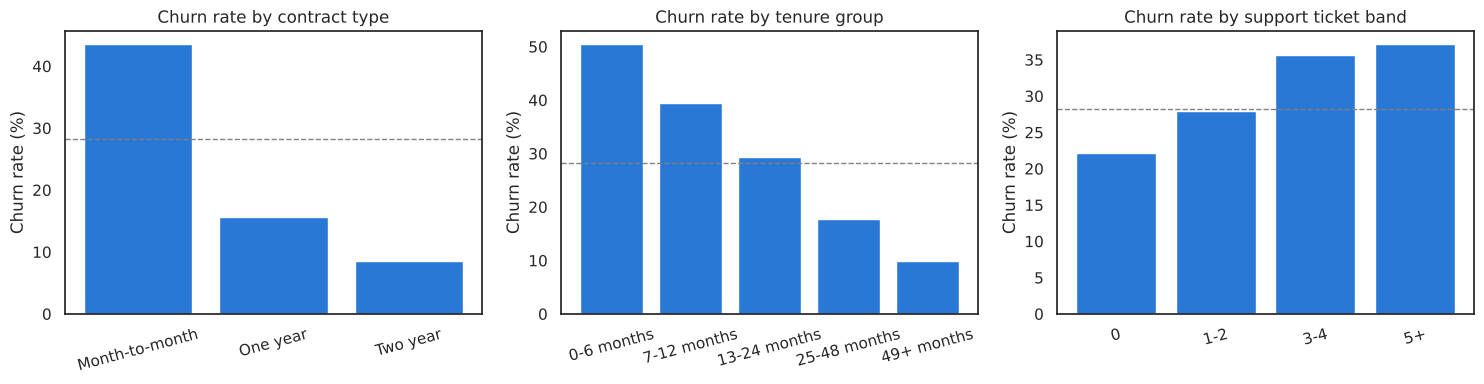

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["contract_type", "tenure_group", "support_ticket_band"]):
    rates = churn_by(col)["churn_rate_%"]
    ax.bar(rates.index.astype(str), rates.values, color="#2a78d6")
    ax.axhline(churned / total * 100, color="gray", linestyle="--", linewidth=1)
    ax.set_title(f"Churn rate by {col.replace('_', ' ')}")
    ax.set_ylabel("Churn rate (%)")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

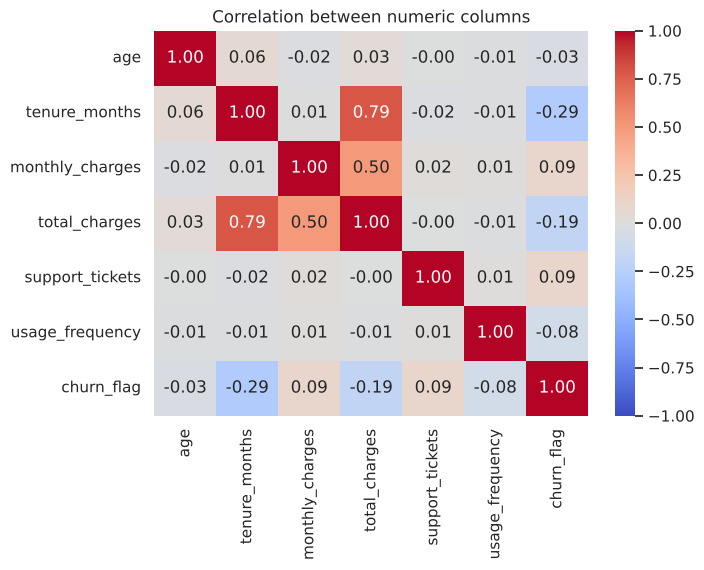

In [28]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation between numeric columns")
plt.show()

## 9. Summary

- Overall churn is 28.2% (1,126 of 3,990 customers).
- Contract type and tenure show the clearest differences: month-to-month 43.5% vs two-year 8.5%, and 0-6 months 50.4% vs 49+ months 9.9%.
- Support tickets, monthly charges, payment method and customer segment also show differences, but smaller ones.
- 225 customers match the high-risk rule (month-to-month, 12 months or less, 3+ tickets). 59.6% of them churned and 91 are still active.

These are patterns in the data, not proof of cause. The full list of insights is in `docs/insights.md`.